# DSA Assignment 1 — Q1: JL for k-means clustering
**Snehil Modi (2024558), Vasu Mehta (2024601)**

All randomness comes from `SEED = 2024558` (numpy `default_rng`), and every KMeans uses `random_state=0`, so every number below can be reproduced. Random matrices are drawn with numpy only (no `sklearn.random_projection`).

In [1]:
import time, json, os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99

SEED = 2024558            # master seed: every random number below is derived from it
os.makedirs("figs", exist_ok=True)
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e1",
                     "grid.linewidth": 0.6, "font.size": 10})
from sklearn.cluster import KMeans
K = 15
MS = [5, 10, 15, 20, 25]
REPS = 5

## Data matrix D

In [2]:
kdd = fetch_kddcup99(subset=None, as_frame=True)
X = kdd.data.copy()
cat_cols = ["protocol_type", "service", "flag"]
for c in cat_cols:                                   # bytes -> str for readable column names
    X[c] = X[c].apply(lambda v: v.decode() if isinstance(v, bytes) else v)
num_cols = [c for c in X.columns if c not in cat_cols]

# (i) one-hot encode the 3 text features, convert the other 38 to float
Df = pd.concat([X[num_cols].astype(float),
                pd.get_dummies(X[cat_cols], prefix=cat_cols, dtype=float)], axis=1)
d_before = Df.shape[1]
# (ii) drop every column that is constant on all rows
const_cols = list(Df.columns[Df.nunique() <= 1])
Df = Df.drop(columns=const_cols)
# (iii) min-max rescale every column to [0, 1]
Df = (Df - Df.min()) / (Df.max() - Df.min())

D = Df.to_numpy(dtype=np.float64)
n, d = D.shape
print(f"columns after one-hot: {d_before}; constant columns dropped: {const_cols}")
print(f"n = {n}, d = {d}, min = {D.min()}, max = {D.max()}")


columns after one-hot: 118; constant columns dropped: ['num_outbound_cmds', 'is_host_login']
n = 494021, d = 116, min = 0.0, max = 1.0


## Helper functions
`cost(D, B)` assigns each row to its nearest centre (done in chunks to keep memory low). `cluster_means` averages the original rows of D within each cluster to give $\hat B$.

In [3]:
def cost(X, B, chunk=100_000):
    """sum_i min_b ||X_i - b||^2"""
    B = np.asarray(B, dtype=np.float64)
    bb = (B ** 2).sum(1)
    total = 0.0
    for s in range(0, X.shape[0], chunk):
        x = X[s:s + chunk]
        d2 = (x ** 2).sum(1)[:, None] - 2 * x @ B.T + bb[None, :]
        total += np.maximum(d2.min(1), 0).sum()
    return float(total)

def cluster_means(X, labels, k=K):
    cnt = np.bincount(labels, minlength=k).astype(float)
    S = np.zeros((k, X.shape[1]))
    np.add.at(S, labels, X)
    keep = cnt > 0                                  # guard against an empty cluster
    return S[keep] / cnt[keep, None]

def partition_cost(X, labels, k=K):
    """cost_X(C) = sum_j sum_{i in C_j} ||X_i - mu_j(X)||^2"""
    mu = cluster_means(X, labels, k)
    full = np.zeros((k, X.shape[1])); full[np.bincount(labels, minlength=k) > 0] = mu
    return float(((X - full[labels]) ** 2).sum())

def draw_A(m, rng):
    return rng.normal(0.0, 1.0 / np.sqrt(m), size=(m, d))      # N(0, 1/m) entries


## (a) k-means on D

In [4]:
t0 = time.perf_counter()
km_D = KMeans(n_clusters=K, n_init=5, random_state=0).fit(D)
time_a = time.perf_counter() - t0
B = km_D.cluster_centers_
labels_D = km_D.labels_                      # clusters C_D
cost_DB = cost(D, B)
print(f"cost(D, B) = {cost_DB:.2f}")
print(f"wall-clock time of k-means on D = {time_a:.2f} s")
print("cluster sizes:", np.bincount(labels_D))


cost(D, B) = 53540.69
wall-clock time of k-means on D = 14.39 s
cluster sizes: [ 20826 280781  86925  30324   8476   5706   5408   5631   9600   6243
    689  28434   2828    856   1294]


## (b), (c), (d) k-means on E = D Aᵀ for m ∈ {5, 10, 15, 20, 25}, 5 runs each
In every run we time *computing E + running k-means* (part d), form $\hat B$ by averaging rows of D in each cluster (part b), and map the k-means centres back with $A^+$ (part c).

In [5]:
rows = []
for m in MS:
    for r in range(REPS):
        rng = np.random.default_rng([SEED, 1, m, r])
        A = draw_A(m, rng)
        t0 = time.perf_counter()
        E = D @ A.T
        km_E = KMeans(n_clusters=K, n_init=5, random_state=0).fit(E)
        t_run = time.perf_counter() - t0
        B_hat = cluster_means(D, km_E.labels_)                  # (b)
        B_plus = km_E.cluster_centers_ @ np.linalg.pinv(A).T     # (c): rows are A^+ a
        c_hat, c_plus = cost(D, B_hat), cost(D, B_plus)
        rows.append(dict(m=m, run=r + 1, cost_Bhat=c_hat, ratio_Bhat=c_hat / cost_DB,
                         cost_Bplus=c_plus, ratio_Bplus=c_plus / cost_DB, time=t_run))
        print(f"m={m:2d} run={r+1}  cost(D,B^)={c_hat:10.1f}  ratio={c_hat/cost_DB:.4f}  "
              f"ratio(B+)={c_plus/cost_DB:.4f}  time={t_run:.2f}s")
runs = pd.DataFrame(rows)


m= 5 run=1  cost(D,B^)=   55403.2  ratio=1.0348  ratio(B+)=78.3863  time=1.81s


m= 5 run=2  cost(D,B^)=   63351.1  ratio=1.1832  ratio(B+)=76.9392  time=2.17s


m= 5 run=3  cost(D,B^)=   68642.5  ratio=1.2821  ratio(B+)=81.7219  time=2.50s


m= 5 run=4  cost(D,B^)=   54607.8  ratio=1.0199  ratio(B+)=81.0245  time=2.03s


m= 5 run=5  cost(D,B^)=   64145.2  ratio=1.1981  ratio(B+)=79.8995  time=1.86s


m=10 run=1  cost(D,B^)=   57190.7  ratio=1.0682  ratio(B+)=73.2063  time=2.71s


... (15 outputs left out)

m=25 run=2  cost(D,B^)=   54533.4  ratio=1.0185  ratio(B+)=59.5231  time=4.62s


m=25 run=3  cost(D,B^)=   54072.1  ratio=1.0099  ratio(B+)=63.4259  time=4.69s


m=25 run=4  cost(D,B^)=   54563.5  ratio=1.0191  ratio(B+)=61.3340  time=4.18s


m=25 run=5  cost(D,B^)=   57024.6  ratio=1.0651  ratio(B+)=65.7414  time=4.91s


In [6]:
summary = runs.groupby("m").agg(
    mean_cost_Bhat=("cost_Bhat", "mean"),
    mean_ratio_Bhat=("ratio_Bhat", "mean"), min_ratio_Bhat=("ratio_Bhat", "min"), max_ratio_Bhat=("ratio_Bhat", "max"),
    mean_ratio_Bplus=("ratio_Bplus", "mean"), min_ratio_Bplus=("ratio_Bplus", "min"), max_ratio_Bplus=("ratio_Bplus", "max"),
    mean_time=("time", "mean")).reset_index()
pd.set_option("display.float_format", "{:.4f}".format)
summary


,m,mean_cost_Bhat,mean_ratio_Bhat,min_ratio_Bhat,max_ratio_Bhat,mean_ratio_Bplus,min_ratio_Bplus,max_ratio_Bplus,mean_time
0,5,61229.9739,1.1436,1.0199,1.2821,79.5943,76.9392,81.7219,2.0746
1,10,56025.2941,1.0464,0.9804,1.1888,76.2487,72.2239,80.0377,2.9597
2,15,55388.4189,1.0345,0.9835,1.0990,73.5717,72.2822,75.1642,3.2203
3,20,55416.4701,1.0350,1.0103,1.0818,68.8906,65.4325,72.1275,3.7366
4,25,55156.2644,1.0302,1.0099,1.0651,62.8548,59.5231,65.7414,4.4808


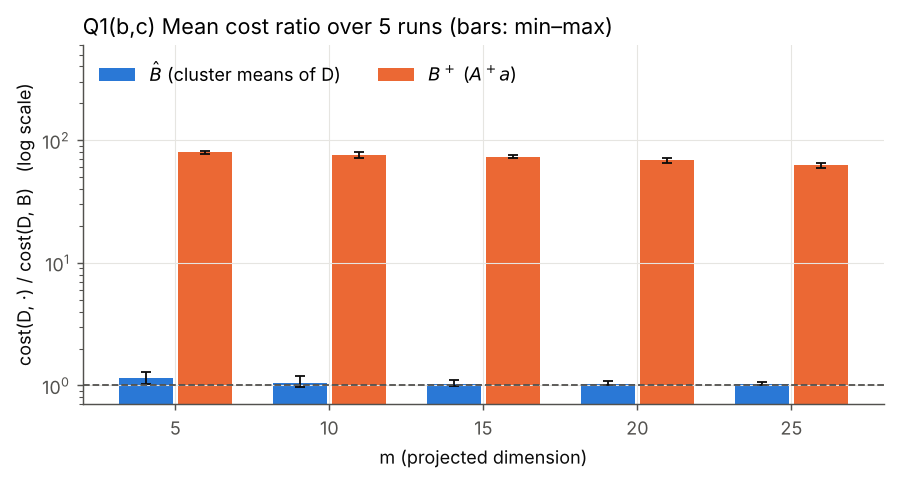

In [7]:
# (b)+(c) bar graph: mean ratio with min-max range as error bars
x = np.arange(len(MS)); w = 0.38
fig, ax = plt.subplots(figsize=(7, 3.8))
for off, col, lab, key in [(-w/2, BLUE, r"$\hat B$ (cluster means of D)", "Bhat"),
                           (w/2, ORANGE, r"$B^+$ ($A^+a$)", "Bplus")]:
    mean = summary[f"mean_ratio_{key}"]; lo = mean - summary[f"min_ratio_{key}"]; hi = summary[f"max_ratio_{key}"] - mean
    ax.bar(x + off, mean, w * 0.92, color=col, label=lab, yerr=[lo, hi], capsize=3,
           error_kw=dict(ecolor=INK, lw=1))
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.set_yscale("log")
ax.set_xticks(x, [str(m) for m in MS]); ax.set_xlabel("m (projected dimension)")
ax.set_ylabel("cost(D, ·) / cost(D, B)   (log scale)")
ax.set_title("Q1(b,c) Mean cost ratio over 5 runs (bars: min–max)", loc="left")
ax.set_ylim(0.7, 600)
ax.legend(frameon=False, loc="upper left", ncol=2)
fig.tight_layout(); fig.savefig("figs/q1_bc_ratio.png", dpi=200); plt.show()


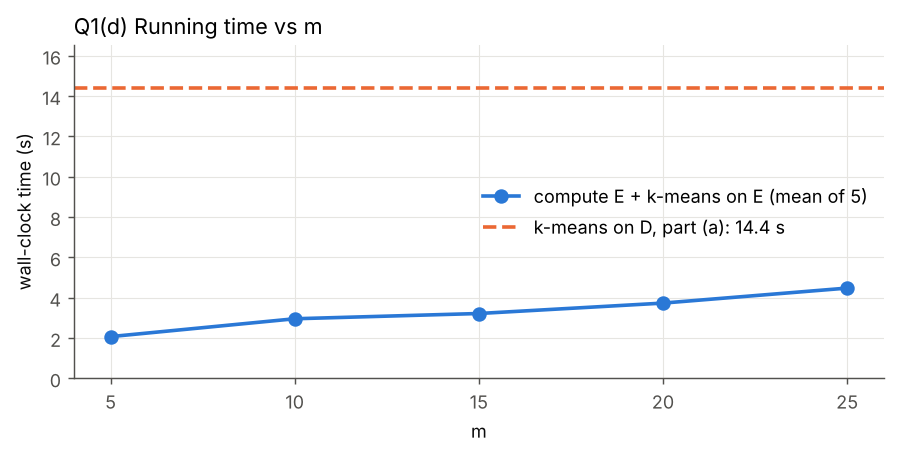

In [8]:
# (d) time of computing E + k-means on E, against m; time of (a) as horizontal line
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(summary["m"], summary["mean_time"], "-o", color=BLUE, lw=2, ms=7, label="compute E + k-means on E (mean of 5)")
ax.axhline(time_a, color=ORANGE, lw=2, ls="--", label=f"k-means on D, part (a): {time_a:.1f} s")
ax.set_xticks(MS); ax.set_xlabel("m"); ax.set_ylabel("wall-clock time (s)")
ax.set_ylim(0, max(time_a, summary["mean_time"].max()) * 1.15)
ax.set_title("Q1(d) Running time vs m", loc="left"); ax.legend(frameon=False, loc="center right")
fig.tight_layout(); fig.savefig("figs/q1_d_time.png", dpi=200); plt.show()


## (e) Distortion of pairwise distances vs distortion of the k-means cost
We pick $10^4$ random pairs with $D_i \ne D_l$ once (fixed seed) and reuse them for every m. For (ii), since $\mu_j(E)=A\mu_j(D)$, $\mathrm{cost}_E(C_D)=\|(D-M)A^\top\|_F^2$ where row i of M is the mean of i's cluster in D.

In [9]:
rng_pairs = np.random.default_rng([SEED, 2])
I, L = [], []
while len(I) < 10_000:
    i = rng_pairs.integers(0, n, 20_000); l = rng_pairs.integers(0, n, 20_000)
    ok = np.any(D[i] != D[l], axis=1)            # keep only pairs with D_i != D_l
    I.extend(i[ok]); L.extend(l[ok])
I, L = np.array(I[:10_000]), np.array(L[:10_000])
diff = D[I] - D[L]
dist_D = (diff ** 2).sum(1)
print("pairs:", len(I), " min ||D_i-D_l||^2 =", dist_D.min())

# residuals of C_D in the original space
mu_D = np.zeros((K, d)); mu_D[:] = cluster_means(D, labels_D)
R = D - mu_D[labels_D]
cost_D_CD = float((R ** 2).sum())
print(f"cost_D(C_D) = {cost_D_CD:.2f}  (equals cost(D,B) up to k-means convergence: {cost_DB:.2f})")

pair_ratio, cost_ratio = {}, {}
for m in MS:
    A = draw_A(m, np.random.default_rng([SEED, 3, m]))              # (i) one draw of A
    pair_ratio[m] = ((diff @ A.T) ** 2).sum(1) / dist_D
    cr = []
    for t in range(20):                                              # (ii) 20 independent draws
        A = draw_A(m, np.random.default_rng([SEED, 4, m, t]))
        cr.append(float(((R @ A.T) ** 2).sum()) / cost_D_CD)
    cost_ratio[m] = np.array(cr)

e_tab = pd.DataFrame({
    "m": MS,
    "pairs: mean": [pair_ratio[m].mean() for m in MS], "pairs: std": [pair_ratio[m].std() for m in MS],
    "pairs: IQR": [np.subtract(*np.percentile(pair_ratio[m], [75, 25])) for m in MS],
    "pairs: min": [pair_ratio[m].min() for m in MS], "pairs: max": [pair_ratio[m].max() for m in MS],
    "cost: mean": [cost_ratio[m].mean() for m in MS], "cost: std": [cost_ratio[m].std() for m in MS],
    "cost: IQR": [np.subtract(*np.percentile(cost_ratio[m], [75, 25])) for m in MS],
    "cost: min": [cost_ratio[m].min() for m in MS], "cost: max": [cost_ratio[m].max() for m in MS]})
e_tab


pairs: 10000  min ||D_i-D_l||^2 = 5.45258899199596e-13


cost_D(C_D) = 53540.69  (equals cost(D,B) up to k-means convergence: 53540.69)


,m,pairs: mean,pairs: std,pairs: IQR,pairs: min,pairs: max,cost: mean,cost: std,cost: IQR,cost: min,cost: max
0,5,0.5535,0.3764,0.5070,0.0157,2.7050,1.0216,0.1819,0.1938,0.7748,1.4022
1,10,1.2536,0.4463,0.7858,0.0659,2.6334,0.9936,0.1187,0.1366,0.7530,1.2844
2,15,0.6689,0.2292,0.2839,0.2376,2.0502,0.9745,0.0745,0.1212,0.8589,1.1552
3,20,0.9875,0.1747,0.1984,0.2651,2.0285,0.9973,0.0866,0.1209,0.8026,1.1245
4,25,0.6725,0.2210,0.2175,0.2407,1.7522,0.9875,0.0508,0.0612,0.9113,1.1020


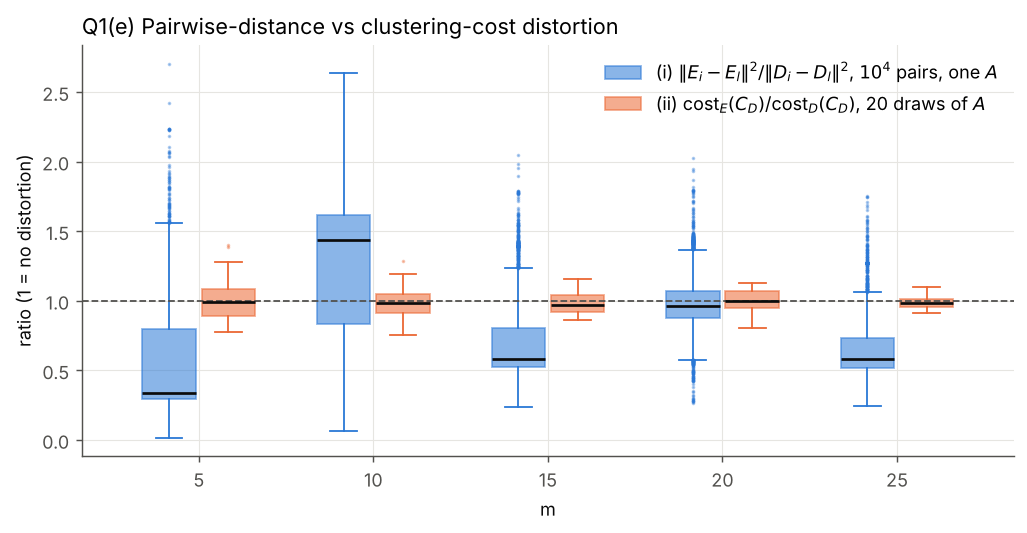

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
pos = np.arange(len(MS)); w = 0.34
def styled_box(data, positions, color):
    bp = ax.boxplot(data, positions=positions, widths=w * 0.9, patch_artist=True, showfliers=True,
                    flierprops=dict(marker=".", ms=2, mfc=color, mec=color, alpha=0.35),
                    medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color=color),
                    capprops=dict(color=color))
    for b in bp["boxes"]:
        b.set(facecolor=color, alpha=0.55, edgecolor=color)
    return bp
b1 = styled_box([pair_ratio[m] for m in MS], pos - w/2, BLUE)
b2 = styled_box([cost_ratio[m] for m in MS], pos + w/2, ORANGE)
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.set_xticks(pos, [str(m) for m in MS]); ax.set_xlabel("m")
ax.set_ylabel("ratio (1 = no distortion)")
ax.legend([b1["boxes"][0], b2["boxes"][0]],
          [r"(i) $\|E_i-E_l\|^2/\|D_i-D_l\|^2$, $10^4$ pairs, one $A$",
           r"(ii) cost$_E(C_D)$/cost$_D(C_D)$, 20 draws of $A$"], frameon=False, loc="upper right")
ax.set_title("Q1(e) Pairwise-distance vs clustering-cost distortion", loc="left")
fig.tight_layout(); fig.savefig("figs/q1_e_box.png", dpi=200); plt.show()


In [11]:
# save every reported number for the PDF report
out = dict(n=n, d=d, d_before=d_before, const_cols=const_cols, cost_DB=cost_DB, time_a=time_a,
           cost_D_CD=cost_D_CD, runs=runs.to_dict("records"), summary=summary.to_dict("records"),
           e_tab=e_tab.to_dict("records"))
json.dump(out, open("results_q1.json", "w"), indent=1)
